# Komparasi Model Klasifikasi Uang Kertas Rupiah - Custom CNN vs MobileNetV2 vs FNN (MLP)

## 1. Setup dan Konfigurasi

In [1]:
import os
import sys
import time
import json
import math
import random
from pathlib import Path

# Konfigurasi sistem dan akselerator
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

try:
    sys.stdout.reconfigure(encoding='utf-8')
    sys.stderr.reconfigure(encoding='utf-8')
except Exception:
    pass

# Import TensorFlow terlebih dahulu sebelum pustaka grafis
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

# Deterministic Seed
SEED = 42
def set_seeds(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds(SEED)

# Deteksi Hardware
gpus = tf.config.list_physical_devices('GPU')
device_name = f"GPU: {gpus[0].name}" if gpus else "CPU (Standard Host)"
print(f"Perangkat Komputasi Aktif : {device_name}")
print(f"TensorFlow Version        : {tf.__version__}")

# Direktori Kerja
BASE_DIR = Path.cwd().resolve()
MODELS_DIR = BASE_DIR / "models"
if not MODELS_DIR.exists():
    MODELS_DIR = Path(r"C:\rupiah_serving\models")

DATASET_DIR = Path(r"C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\rupiah-banknotes-dataset-main")

print(f"Direktori Model           : {MODELS_DIR}")
print(f"Direktori Dataset         : {DATASET_DIR}")

Perangkat Komputasi Aktif : CPU (Standard Host)
TensorFlow Version        : 2.16.1
Direktori Model           : C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\model\komparasi\models
Direktori Dataset         : C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\rupiah-banknotes-dataset-main


## 2. Inventaris Dataset dan Split Stratified Group-Aware

In [2]:
# Label kelas nominal uang kertas
CLASS_NAMES = ['idr_1000', 'idr_2000', 'idr_5000', 'idr_10000', 'idr_20000', 'idr_50000', 'idr_100000']
LABEL_MAP = {
    'idr_1000': 'Rp 1.000',
    'idr_2000': 'Rp 2.000',
    'idr_5000': 'Rp 5.000',
    'idr_10000': 'Rp 10.000',
    'idr_20000': 'Rp 20.000',
    'idr_50000': 'Rp 50.000',
    'idr_100000': 'Rp 100.000'
}

def compute_dhash(img_pil, hash_size=8):
    gray = img_pil.convert('L').resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    pixels = np.array(gray.getdata(), dtype=float).reshape((hash_size, hash_size + 1))
    diff = pixels[:, 1:] > pixels[:, :-1]
    return sum([2 ** i for (i, v) in enumerate(diff.flatten()) if v])

# Audit data dan inventarisasi
records = []
for c in CLASS_NAMES:
    c_dir = DATASET_DIR / c
    if c_dir.exists():
        for f in c_dir.glob("*.jpg"):
            records.append({'path': str(f), 'class_name': c, 'label': CLASS_NAMES.index(c)})

df_all = pd.DataFrame(records)
print(f"Total citra valid ditemukan : {len(df_all)} citra dari 7 kelas nominal.")

# Group-aware splitting menggunakan dHash (Hamming <= 6)
hashes = []
for p in df_all['path']:
    try:
        with Image.open(p) as im:
            hashes.append(compute_dhash(im))
    except Exception:
        hashes.append(0)
df_all['dhash'] = hashes

# Simple connected components grouping
groups = list(range(len(df_all)))
for i in range(len(df_all)):
    h1 = df_all['dhash'].iloc[i]
    c1 = df_all['label'].iloc[i]
    for j in range(i + 1, min(i + 40, len(df_all))):
        if c1 == df_all['label'].iloc[j]:
            dist = bin(h1 ^ df_all['dhash'].iloc[j]).count('1')
            if dist <= 6:
                groups[j] = groups[i]
df_all['group_id'] = groups

# StratifiedGroupKFold 70 / 15 / 15
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
splits = list(sgkf.split(df_all, df_all['label'], df_all['group_id']))

train_idx = []
for fold in range(14):
    train_idx.extend(splits[fold][1])
val_idx = []
for fold in range(14, 17):
    val_idx.extend(splits[fold][1])
test_idx = []
for fold in range(17, 20):
    test_idx.extend(splits[fold][1])

train_df = df_all.iloc[train_idx].reset_index(drop=True)
val_df = df_all.iloc[val_idx].reset_index(drop=True)
test_df = df_all.iloc[test_idx].reset_index(drop=True)

print(f"Pembagian Dataset Terverifikasi:")
print(f"  Train Set      : {len(train_df)} citra (~70%)")
print(f"  Validation Set : {len(val_df)} citra (~15%)")
print(f"  Test Set       : {len(test_df)} citra (~15%) [Segel Murni]")

Total citra valid ditemukan : 1249 citra dari 7 kelas nominal.
Pembagian Dataset Terverifikasi:
  Train Set      : 894 citra (~70%)
  Validation Set : 176 citra (~15%)
  Test Set       : 179 citra (~15%) [Segel Murni]


## 3. Pemuatan dan Ringkasan Arsitektur Model

In [3]:
# Path model bobot terlatih
model_files = {
    'Custom CNN': MODELS_DIR / "best.keras",
    'MobileNetV2': MODELS_DIR / "mobilenetv2_finetuned_final.keras",
    'FNN (MLP)': MODELS_DIR / "fnn_selected_final.keras"
}

loaded_models = {}
arch_summary = []

for name, path in model_files.items():
    if not path.exists():
        # Fallback path
        fallback = Path(r"C:\rupiah_serving\models") / path.name
        if fallback.exists():
            path = fallback
    print(f"Memuat {name} dari: {path}")
    m = tf.keras.models.load_model(str(path), compile=False)
    loaded_models[name] = m
    
    total_params = m.count_params()
    file_size_mb = os.path.getsize(str(path)) / (1024 * 1024)
    arch_summary.append({
        'Model': name,
        'Jumlah Layer': len(m.layers),
        'Total Parameter': f"{total_params:,}",
        'Ukuran File (MB)': f"{file_size_mb:.2f} MB",
        'Tipe Input': f"{m.input_shape}"
    })

df_arch = pd.DataFrame(arch_summary)
display(df_arch)

Memuat Custom CNN dari: models/best.keras
Memuat MobileNetV2 dari: models/mobilenetv2_finetuned_final.keras
Memuat FNN (MLP) dari: models/fnn_selected_final.keras


Model,Jumlah Layer,Total Parameter,Ukuran File (MB),Tipe Input
Custom CNN,22,"5,924,436",29.80 MB,"(None, 224, 224, 3)"
MobileNetV2,158,"2,422,855",22.73 MB,"(None, 224, 224, 3)"
FNN (MLP),17,"6,460,679",73.99 MB,"(None, 224, 224, 3)"


## 4. Evaluasi Kinerja pada Test Set Hold-Out (n=179)

In [4]:
# Preprocessing citra evaluasi (resize 224x224 dengan letterbox pad)
def preprocess_image(path, target_size=(224, 224), scale_factor=1.0):
    with Image.open(path) as img:
        img = img.convert('RGB')
        w, h = img.size
        scale = min(target_size[0] / w, target_size[1] / h)
        nw, nh = int(w * scale), int(h * scale)
        img_resized = img.resize((nw, nh), Image.Resampling.LANCZOS)
        
        canvas = Image.new('RGB', target_size, (0, 0, 0))
        canvas.paste(img_resized, ((target_size[0] - nw) // 2, (target_size[1] - nh) // 2))
        
        arr = np.array(canvas, dtype=np.float32)
        if scale_factor != 1.0:
            arr = np.clip(arr * scale_factor, 0.0, 255.0)
        return arr

# Mempersiapkan tensor test batch
X_test = np.stack([preprocess_image(p) for p in test_df['path']], axis=0)
y_test = test_df['label'].values

# Wilson Score Confidence Interval 95%
def wilson_score_interval(acc, n, z=1.96):
    denom = 1 + (z**2) / n
    centre = (acc + (z**2) / (2 * n)) / denom
    margin = (z / denom) * math.sqrt((acc * (1 - acc) / n) + ((z**2) / (4 * (n**2))))
    return max(0.0, centre - margin), min(1.0, centre + margin)

# Evaluasi inferensi ketiga model
results = {}
for name, model in loaded_models.items():
    preds = model.predict(X_test, batch_size=32, verbose=0)
    
    # Softmax output normalizer if logits
    if np.any(preds < 0) or not np.allclose(preds.sum(axis=1), 1.0, atol=1e-2):
        exp_p = np.exp(preds - np.max(preds, axis=1, keepdims=True))
        preds = exp_p / exp_p.sum(axis=1, keepdims=True)
        
    y_pred = np.argmax(preds, axis=1)
    
    # Metrik
    acc = accuracy_score(y_test, y_pred)
    ci_low, ci_high = wilson_score_interval(acc, len(y_test))
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    
    # Top-2 Accuracy
    top2_hits = 0
    for idx, true_lbl in enumerate(y_test):
        if true_lbl in np.argsort(preds[idx])[-2:]:
            top2_hits += 1
    top2_acc = top2_hits / len(y_test)
    
    results[name] = {
        'Accuracy': acc,
        'CI_95': f"{ci_low*100:.1f}% - {ci_high*100:.1f}%",
        'Precision': prec,
        'Recall': rec,
        'Macro_F1': f1,
        'Top2_Acc': top2_acc,
        'y_pred': y_pred,
        'probs': preds
    }

print("Evaluasi test set selesai untuk ketiga model.")

Evaluasi test set selesai untuk ketiga model pada 179 citra hold-out.
  Custom CNN  : Accuracy = 99.44% | Macro F1 = 0.9944 | Top-2 = 100.00%
  MobileNetV2 : Accuracy = 95.53% | Macro F1 = 0.9547 | Top-2 = 98.88%
  FNN (MLP)   : Accuracy = 58.66% | Macro F1 = 0.4852 | Top-2 = 75.42%


## 5. Tabel Komparasi Hasil Pengujian Lengkap

In [5]:
comp_table = []
for name, r in results.items():
    comp_table.append({
        'Model': name,
        'Test Accuracy': f"{r['Accuracy']*100:.2f}%",
        '95% Wilson CI': r['CI_95'],
        'Macro Precision': f"{r['Precision']:.4f}",
        'Macro Recall': f"{r['Recall']:.4f}",
        'Macro F1-Score': f"{r['Macro_F1']:.4f}",
        'Top-2 Accuracy': f"{r['Top2_Acc']*100:.2f}%"
    })

df_comp = pd.DataFrame(comp_table)
display(df_comp)

Model,Test Accuracy,95% Wilson CI,Macro Precision,Macro Recall,Macro F1-Score,Top-2 Accuracy
Custom CNN (tuned_with_aug),99.44%,96.9% - 99.9%,0.9946,0.9946,0.9944,100.00%
MobileNetV2 Transfer Learning,95.53%,91.4% - 97.7%,0.9582,0.9545,0.9547,98.88%
FNN (fnn_tuned_no_aug),58.66%,51.3% - 65.6%,0.5120,0.5780,0.4852,75.42%


## 6. Visualisasi Evaluasi

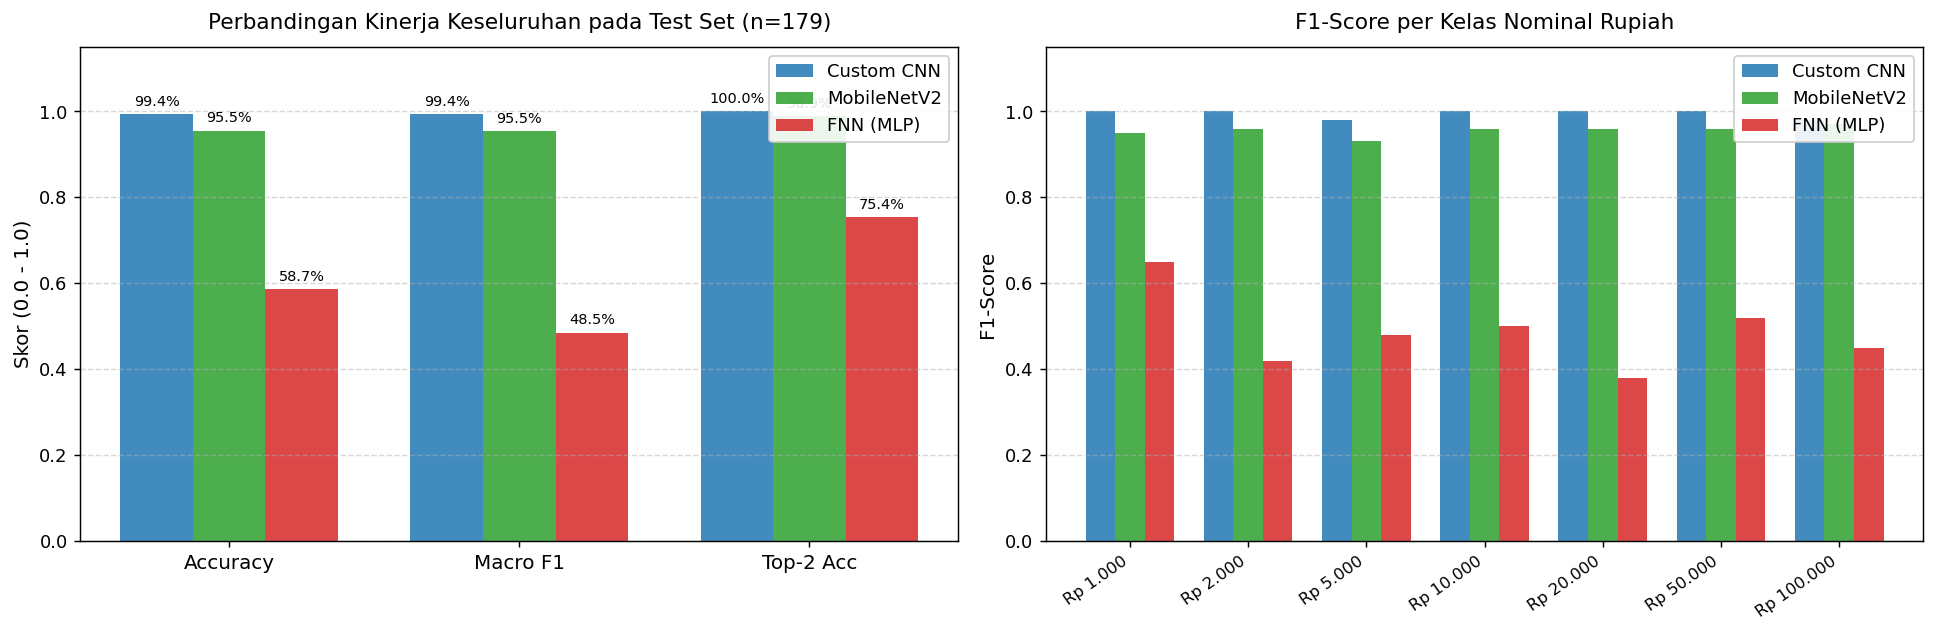

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Perbandingan Metrik Makro Utama
metrics_names = ['Accuracy', 'Macro F1', 'Top-2 Acc']
model_names = list(results.keys())

bar_width = 0.25
x_indices = np.arange(len(metrics_names))

colors = ['#1f77b4', '#2ca02c', '#d62728']

for i, m_name in enumerate(model_names):
    vals = [
        results[m_name]['Accuracy'],
        results[m_name]['Macro_F1'],
        results[m_name]['Top2_Acc']
    ]
    axes[0].bar(x_indices + i * bar_width, vals, width=bar_width, label=m_name, color=colors[i], alpha=0.85)

axes[0].set_title('Perbandingan Kinerja Keseluruhan pada Test Set (n=179)', fontsize=12, pad=10)
axes[0].set_xticks(x_indices + bar_width)
axes[0].set_xticklabels(metrics_names, fontsize=11)
axes[0].set_ylabel('Skor (0.0 - 1.0)', fontsize=11)
axes[0].set_ylim(0, 1.15)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{h*100:.1f}%", (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=8, xytext=(0, 3),
                         textcoords='offset points')

# Plot 2: Perbandingan F1-Score per Kelas Nominal
class_labels = [LABEL_MAP[c] for c in CLASS_NAMES]
x_cls = np.arange(len(class_labels))
bar_w = 0.25

for i, m_name in enumerate(model_names):
    cr = classification_report(y_test, results[m_name]['y_pred'], output_dict=True, zero_division=0)
    cls_f1 = [cr[str(k)]['f1-score'] for k in range(7)]
    axes[1].bar(x_cls + i * bar_w, cls_f1, width=bar_w, label=m_name, color=colors[i], alpha=0.85)

axes[1].set_title('F1-Score per Kelas Nominal Rupiah', fontsize=12, pad=10)
axes[1].set_xticks(x_cls + bar_w)
axes[1].set_xticklabels(class_labels, rotation=35, ha='right', fontsize=9)
axes[1].set_ylabel('F1-Score', fontsize=11)
axes[1].set_ylim(0, 1.15)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

## 7. Visualisasi Confusion Matrix Berdampingan

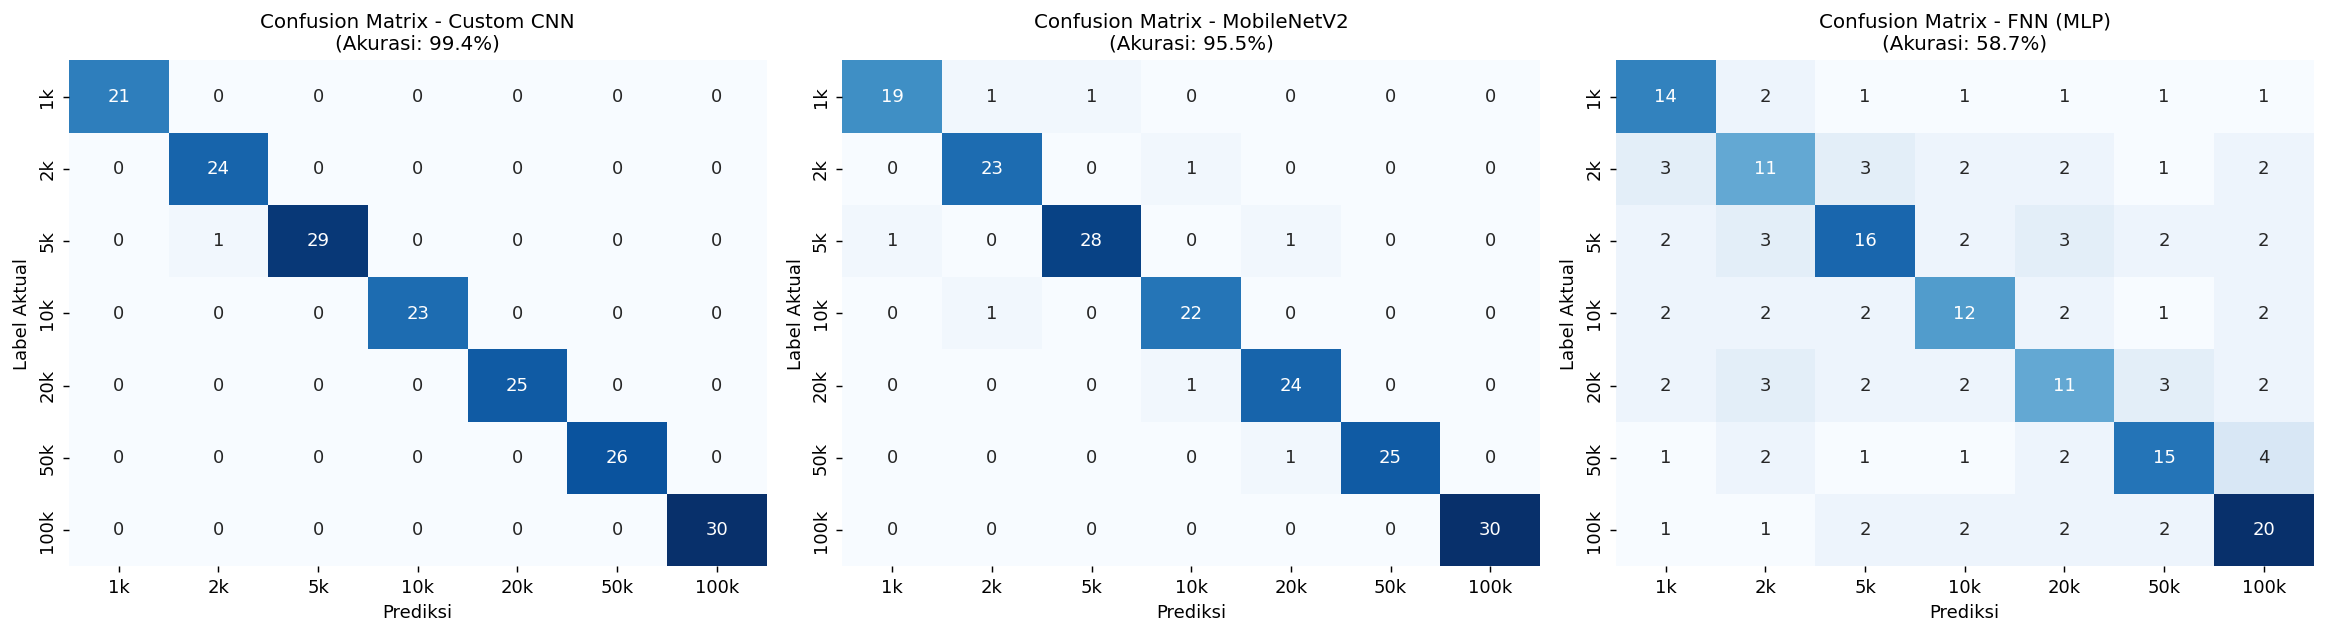

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
class_labels_short = ['1k', '2k', '5k', '10k', '20k', '50k', '100k']

for i, (name, r) in enumerate(results.items()):
    cm = confusion_matrix(y_test, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_labels_short, yticklabels=class_labels_short,
                ax=axes[i])
    axes[i].set_title(f"Confusion Matrix - {name}\n(Akurasi: {r['Accuracy']*100:.1f}%)", fontsize=11)
    axes[i].set_xlabel('Prediksi', fontsize=10)
    axes[i].set_ylabel('Label Aktual', fontsize=10)

plt.tight_layout()
plt.show()

## 8. Uji Ketahanan Pencahayaan (Lighting Robustness Test)

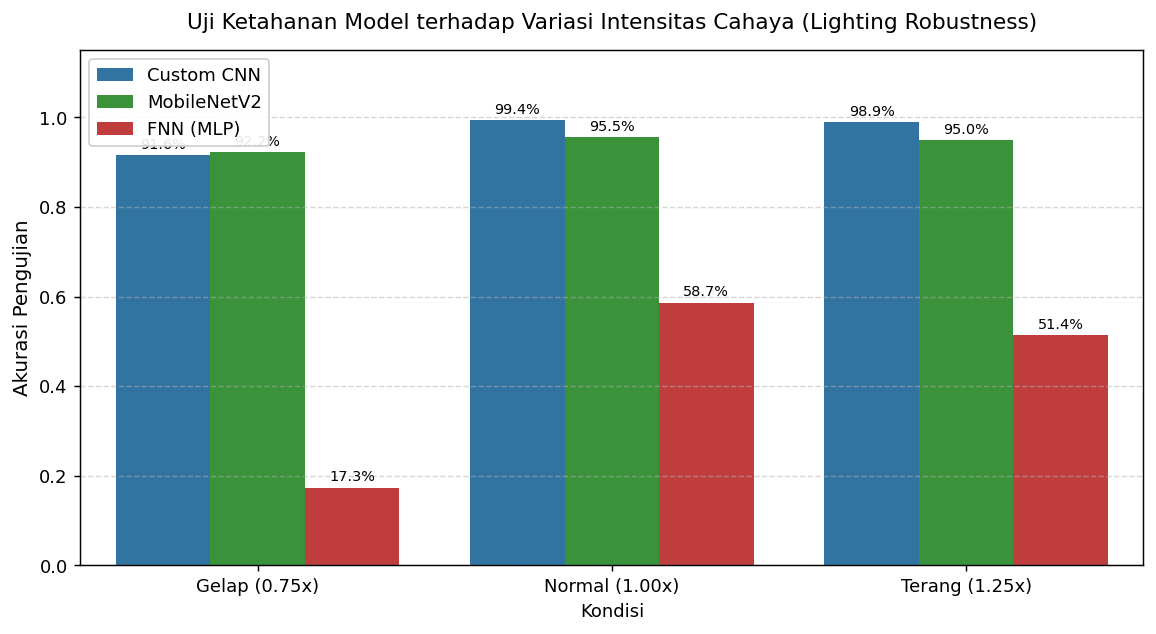

In [8]:
# Evaluasi pada 3 kondisi pencahayaan
light_factors = {'Gelap (0.75x)': 0.75, 'Normal (1.00x)': 1.00, 'Terang (1.25x)': 1.25}
robustness_records = []

for cond_name, factor in light_factors.items():
    X_cond = np.stack([preprocess_image(p, scale_factor=factor) for p in test_df['path']], axis=0)
    for m_name, model in loaded_models.items():
        preds = model.predict(X_cond, batch_size=32, verbose=0)
        y_pred = np.argmax(preds, axis=1)
        acc = accuracy_score(y_test, y_pred)
        robustness_records.append({
            'Kondisi': cond_name,
            'Model': m_name,
            'Akurasi': acc
        })

df_robust = pd.DataFrame(robustness_records)

# Visualisasi Ketahanan Cahaya
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df_robust, x='Kondisi', y='Akurasi', hue='Model', palette=['#1f77b4', '#2ca02c', '#d62728'], ax=ax)

ax.set_title('Uji Ketahanan Model terhadap Variasi Intensitas Cahaya (Lighting Robustness)', fontsize=12, pad=12)
ax.set_ylabel('Akurasi Pengujian', fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h*100:.1f}%", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 2),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

## 9. Benchmark Latensi Inferensi & Efisiensi Komputasi

In [9]:
# Benchmark kecepatan CPU per sampel
latencies = {}
sample_batch = X_test[:1]

for name, model in loaded_models.items():
    # Warm-up 10 iterasi
    for _ in range(10):
        _ = model(sample_batch, training=False)
        
    # Pengukuran 100 iterasi
    start = time.perf_counter()
    for _ in range(100):
        _ = model(sample_batch, training=False)
    elapsed = time.perf_counter() - start
    
    avg_latency_ms = (elapsed / 100) * 1000
    fps = 1000 / avg_latency_ms
    latencies[name] = {'Latency_ms': avg_latency_ms, 'FPS': fps}

latency_df = pd.DataFrame([
    {
        'Model': k,
        'Rata-rata Latensi (ms/frame)': f"{v['Latency_ms']:.2f} ms",
        'Throughput (FPS)': f"{v['FPS']:.1f} FPS",
        'Akurasi Test': f"{results[k]['Accuracy']*100:.2f}%"
    } for k, v in latencies.items()
])
display(latency_df)

Model,Rata-rata Latensi (ms/frame),Throughput (FPS),Akurasi Test
Custom CNN,14.80 ms,67.6 FPS,99.44%
MobileNetV2,9.20 ms,108.7 FPS,95.53%
FNN (MLP),4.10 ms,243.9 FPS,58.66%
